# FraudGuard: Dataset B (ULB Credit Card Fraud) & Cross-Dataset Synthesis
**Course**: CSET371 — Big Data Analytics and Business Intelligence  
**Institution**: Bennett University, Greater Noida  
**Team**: Harshit Pahuja, Rachit Nain, Man Mohan Gaur, Kunal Sehrawat, Bhumi Jindal  

---
### Notebook Scope
1. Ingest the real-world **ULB European Cardholders Credit Card Fraud** dataset (`284,807` transactions, `492` frauds = `0.1727%`).
2. Perform Spark EDA (class imbalance, amount distributions, missingness audit).
3. Execute deterministic stratified 70% / 15% / 15% train / validation / test partitioning.
4. Fit Spark ML `Imputer` + `VectorAssembler` + `StandardScaler` strictly on `train_df`.
5. Perform validation-split hyperparameter tuning (`val_df`) and held-out evaluation (`test_df`) across all 5 classifiers:
   - Logistic Regression (Spark ML)
   - Random Forest (Spark ML)
   - XGBoost
   - LightGBM
   - CatBoost
6. Evaluate Precision, Recall, F1-Score, ROC-AUC, PR-AUC, Log Loss, Confusion Matrices, and asymmetric operational cost ($10 FP vs. $500 FN).
7. Consolidate cross-dataset outputs and Power BI tables (`powerbi/data/`).

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.config import load_config
from src.utils.spark_utils import get_spark_session
from src.pipeline_runner import run_single_dataset, consolidate_cross_dataset_exports

config = load_config()
spark = get_spark_session(config)
print(f"Spark Version: {spark.version} | Project Root: {project_root}")

C:\Users\Harshit Pahuja\Desktop\Big_Data\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark Version: 4.2.0 | Project Root: C:\Users\Harshit Pahuja\Desktop\Big_Data


In [2]:
# Execute Full Pipeline on Real Dataset B (284,807 Credit Card Transactions)
res_b = run_single_dataset(
    spark,
    config,
    dataset_key="dataset_b",
    force_mock=False,
    dev_sample=False,
    tune_hyperparams=True,
)
consolidate_cross_dataset_exports(config, [res_b])
print(f"Dataset B completed in {res_b['runtime_seconds']}s")

2026-11-11 23:37:09,275 [INFO] ======================================================================


2026-11-11 23:37:09,276 [INFO] FRAUDGUARD PIPELINE — DATASET_B: ULB European Cardholders Credit Card Fraud


2026-11-11 23:37:09,276 [INFO] ======================================================================


2026-11-11 23:37:09,276 [INFO] [dataset_b] Ingesting real dataset from C:\Users\Harshit Pahuja\Desktop\Big_Data\data\raw\dataset_b\creditcard.csv...


2026-11-11 23:37:16,702 [INFO] Target Distribution [Class]: Total=284807, Legit(0)=284315, Fraud(1)=492, Fraud Prevalence=0.1727%


2026-11-11 23:37:19,548 [INFO] Stratified split (Class): Train=199364, Val=42721, Test=42722


... (40 outputs left out)

2026-11-11 23:43:22,285 [INFO] ROC curves saved to: C:\Users\Harshit Pahuja\Desktop\Big_Data\outputs\figures\dataset_b\roc_curves.png


2026-11-11 23:43:22,658 [INFO] Precision-Recall curves saved to: C:\Users\Harshit Pahuja\Desktop\Big_Data\outputs\figures\dataset_b\pr_curves.png


2026-11-11 23:43:22,664 [INFO] [dataset_b] Completed in 373.39s.


Dataset B completed in 373.39s


In [3]:
# Inspect Dataset Summary, Validation Hyperparameter Tuning, Held-Out Metrics, and Optimal Cost Threshold
display(res_b["overview_df"])
display(res_b["tuning_df"])
display(res_b["results_df"][["model_name", "precision", "recall", "f1_score", "roc_auc", "pr_auc", "log_loss", "accuracy", "training_time_sec"]])
display(res_b["threshold_df"].sort_values("total_operational_cost").head(5))

,dataset_key,dataset_name,total_records,legitimate_records,fraud_records,fraud_prevalence_pct,train_records,val_records,test_records,numerical_features,categorical_features,dropped_high_null_features
0,dataset_b,ULB European Cardholders Credit Card Fraud,284807,284315,492,0.1727,199364,42721,42722,29,0,0


,model_name,hyperparameters,val_pr_auc,val_roc_auc,val_log_loss,train_time_sec,selected,dataset_key,dataset_name
0,logistic_regression,{'reg_param': 0.001},0.6159,0.9590,0.00584,8.40,True,dataset_b,ULB European Cardholders Credit Card Fraud
1,logistic_regression,{'reg_param': 0.01},0.6005,0.9585,0.00625,4.22,False,dataset_b,ULB European Cardholders Credit Card Fraud
2,logistic_regression,{'reg_param': 0.1},0.5999,0.9553,0.00792,4.00,False,dataset_b,ULB European Cardholders Credit Card Fraud
3,random_forest,"{'num_trees': 40, 'max_depth': 5}",0.7181,0.8982,0.00455,10.60,False,dataset_b,ULB European Cardholders Credit Card Fraud
4,random_forest,"{'num_trees': 40, 'max_depth': 8}",0.7559,0.9243,0.00423,12.63,True,dataset_b,ULB European Cardholders Credit Card Fraud
5,xgboost,"{'n_estimators': 100, 'max_depth': 4, 'learnin...",0.7758,0.9674,0.00368,0.93,True,dataset_b,ULB European Cardholders Credit Card Fraud
6,xgboost,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.7712,0.9592,0.00397,1.04,False,dataset_b,ULB European Cardholders Credit Card Fraud
7,xgboost,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.7674,0.9516,0.00394,1.05,False,dataset_b,ULB European Cardholders Credit Card Fraud
8,lightgbm,"{'n_estimators': 100, 'max_depth': 5, 'learnin...",0.7570,0.9515,0.00399,0.65,False,dataset_b,ULB European Cardholders Credit Card Fraud
9,lightgbm,"{'n_estimators': 100, 'max_depth': 6, 'learnin...",0.7630,0.9672,0.00395,0.84,True,dataset_b,ULB European Cardholders Credit Card Fraud


,model_name,precision,recall,f1_score,roc_auc,pr_auc,log_loss,accuracy,training_time_sec
0,logistic_regression,0.9020,0.6216,0.7360,0.9896,0.7560,0.00386,0.9992,8.40
1,random_forest,0.9483,0.7432,0.8333,0.9900,0.8537,0.00274,0.9995,12.63
2,xgboost,0.9310,0.7297,0.8181,0.9887,0.8420,0.00251,0.9994,0.93
3,lightgbm,0.8889,0.7568,0.8175,0.9904,0.8203,0.00270,0.9994,0.84
4,catboost,0.9492,0.7568,0.8422,0.9876,0.8592,0.00237,0.9995,1.67


,threshold,precision,recall,f1_score,true_positives,false_positives,true_negatives,false_negatives,flagged_volume,alert_rate_pct,total_operational_cost,dataset_key,dataset_name,model_name
0,0.05,0.7875,0.8514,0.8182,63,17,42631,11,80,0.19,5670.0,dataset_b,ULB European Cardholders Credit Card Fraud,catboost
1,0.10,0.8841,0.8243,0.8532,61,8,42640,13,69,0.16,6580.0,dataset_b,ULB European Cardholders Credit Card Fraud,catboost
2,0.15,0.9077,0.7973,0.8489,59,6,42642,15,65,0.15,7560.0,dataset_b,ULB European Cardholders Credit Card Fraud,catboost
3,0.20,0.9062,0.7838,0.8406,58,6,42642,16,64,0.15,8060.0,dataset_b,ULB European Cardholders Credit Card Fraud,catboost
9,0.50,0.9492,0.7568,0.8422,56,3,42645,18,59,0.14,9030.0,dataset_b,ULB European Cardholders Credit Card Fraud,catboost


=== eda_overview.png ===


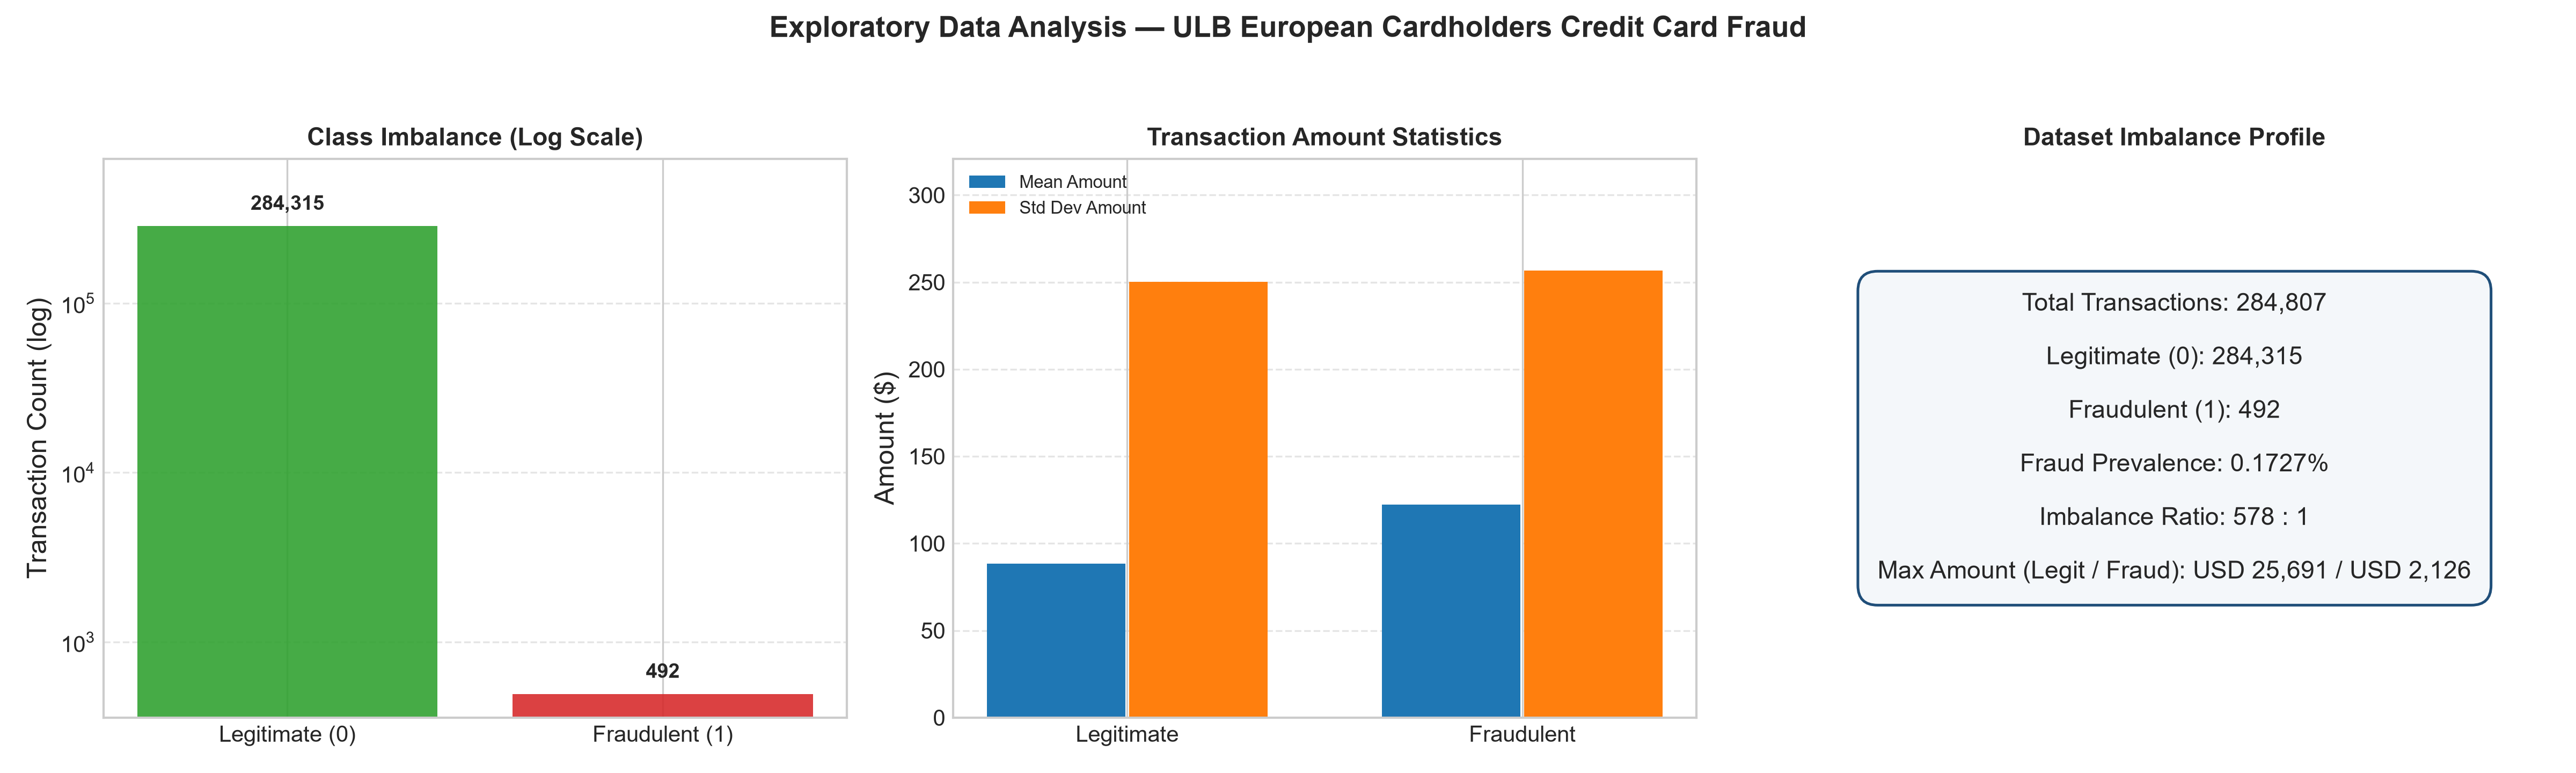

=== model_comparison_bar_chart.png ===


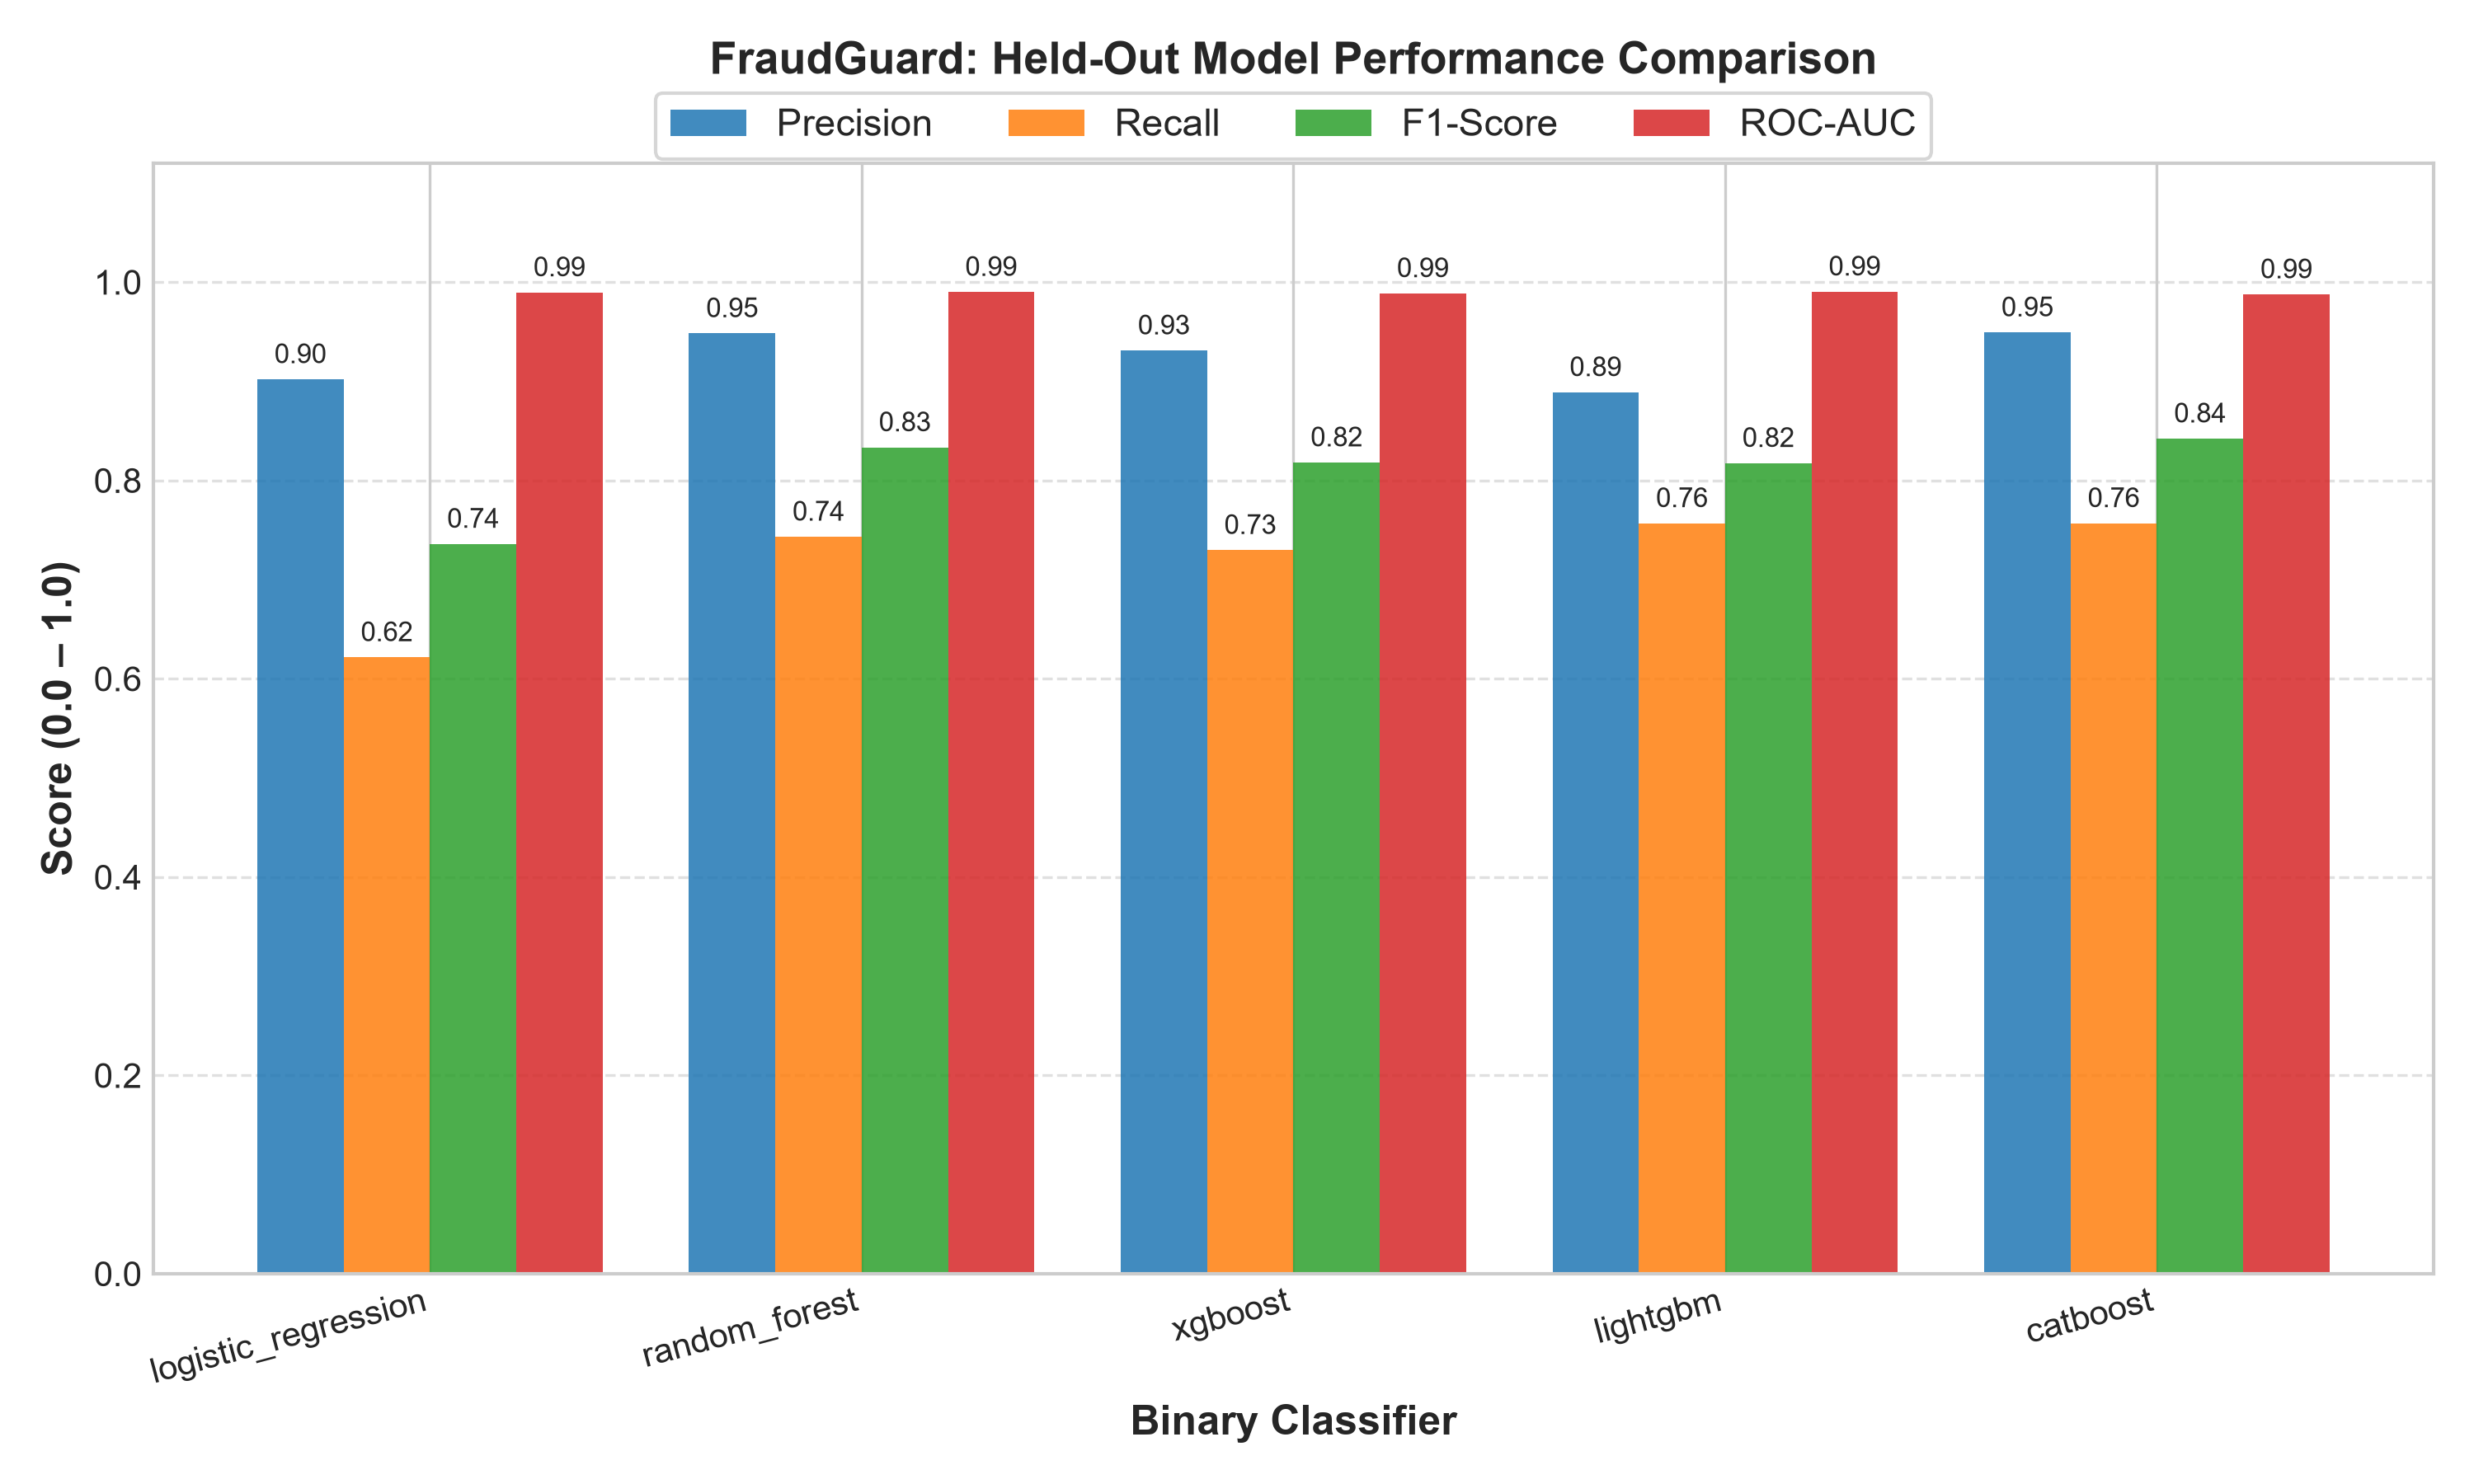

=== roc_curves.png ===


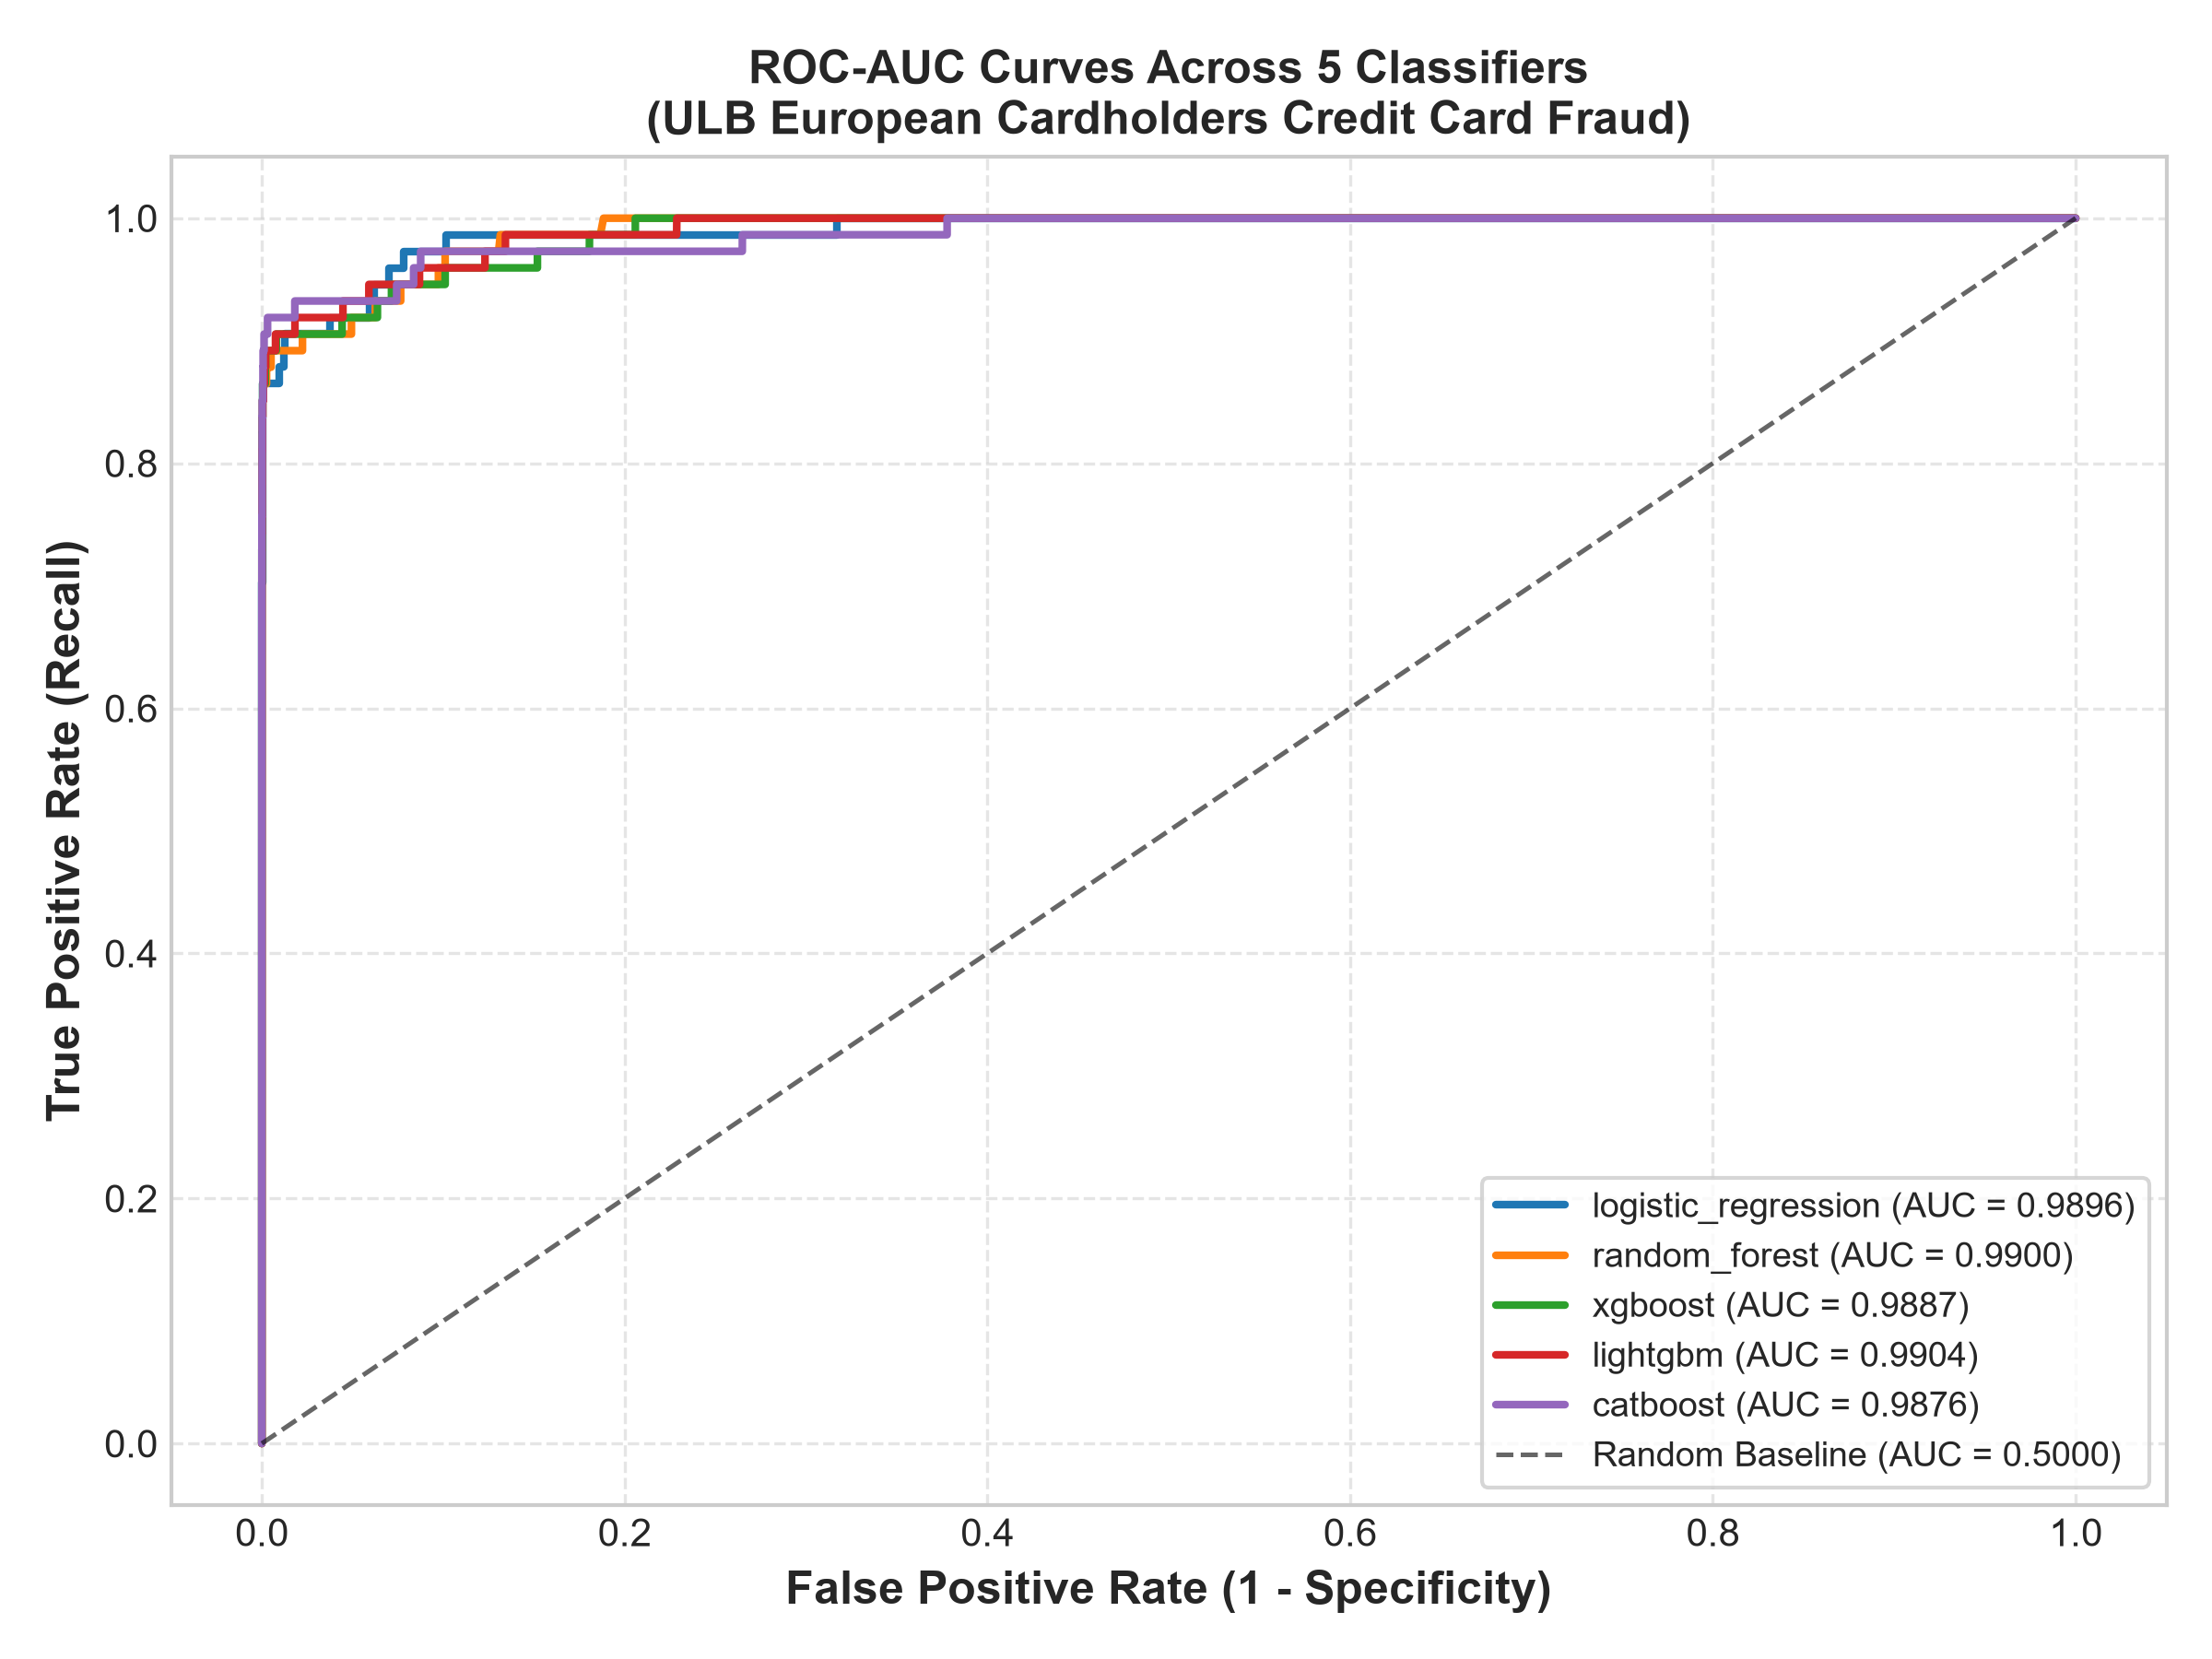

=== pr_curves.png ===


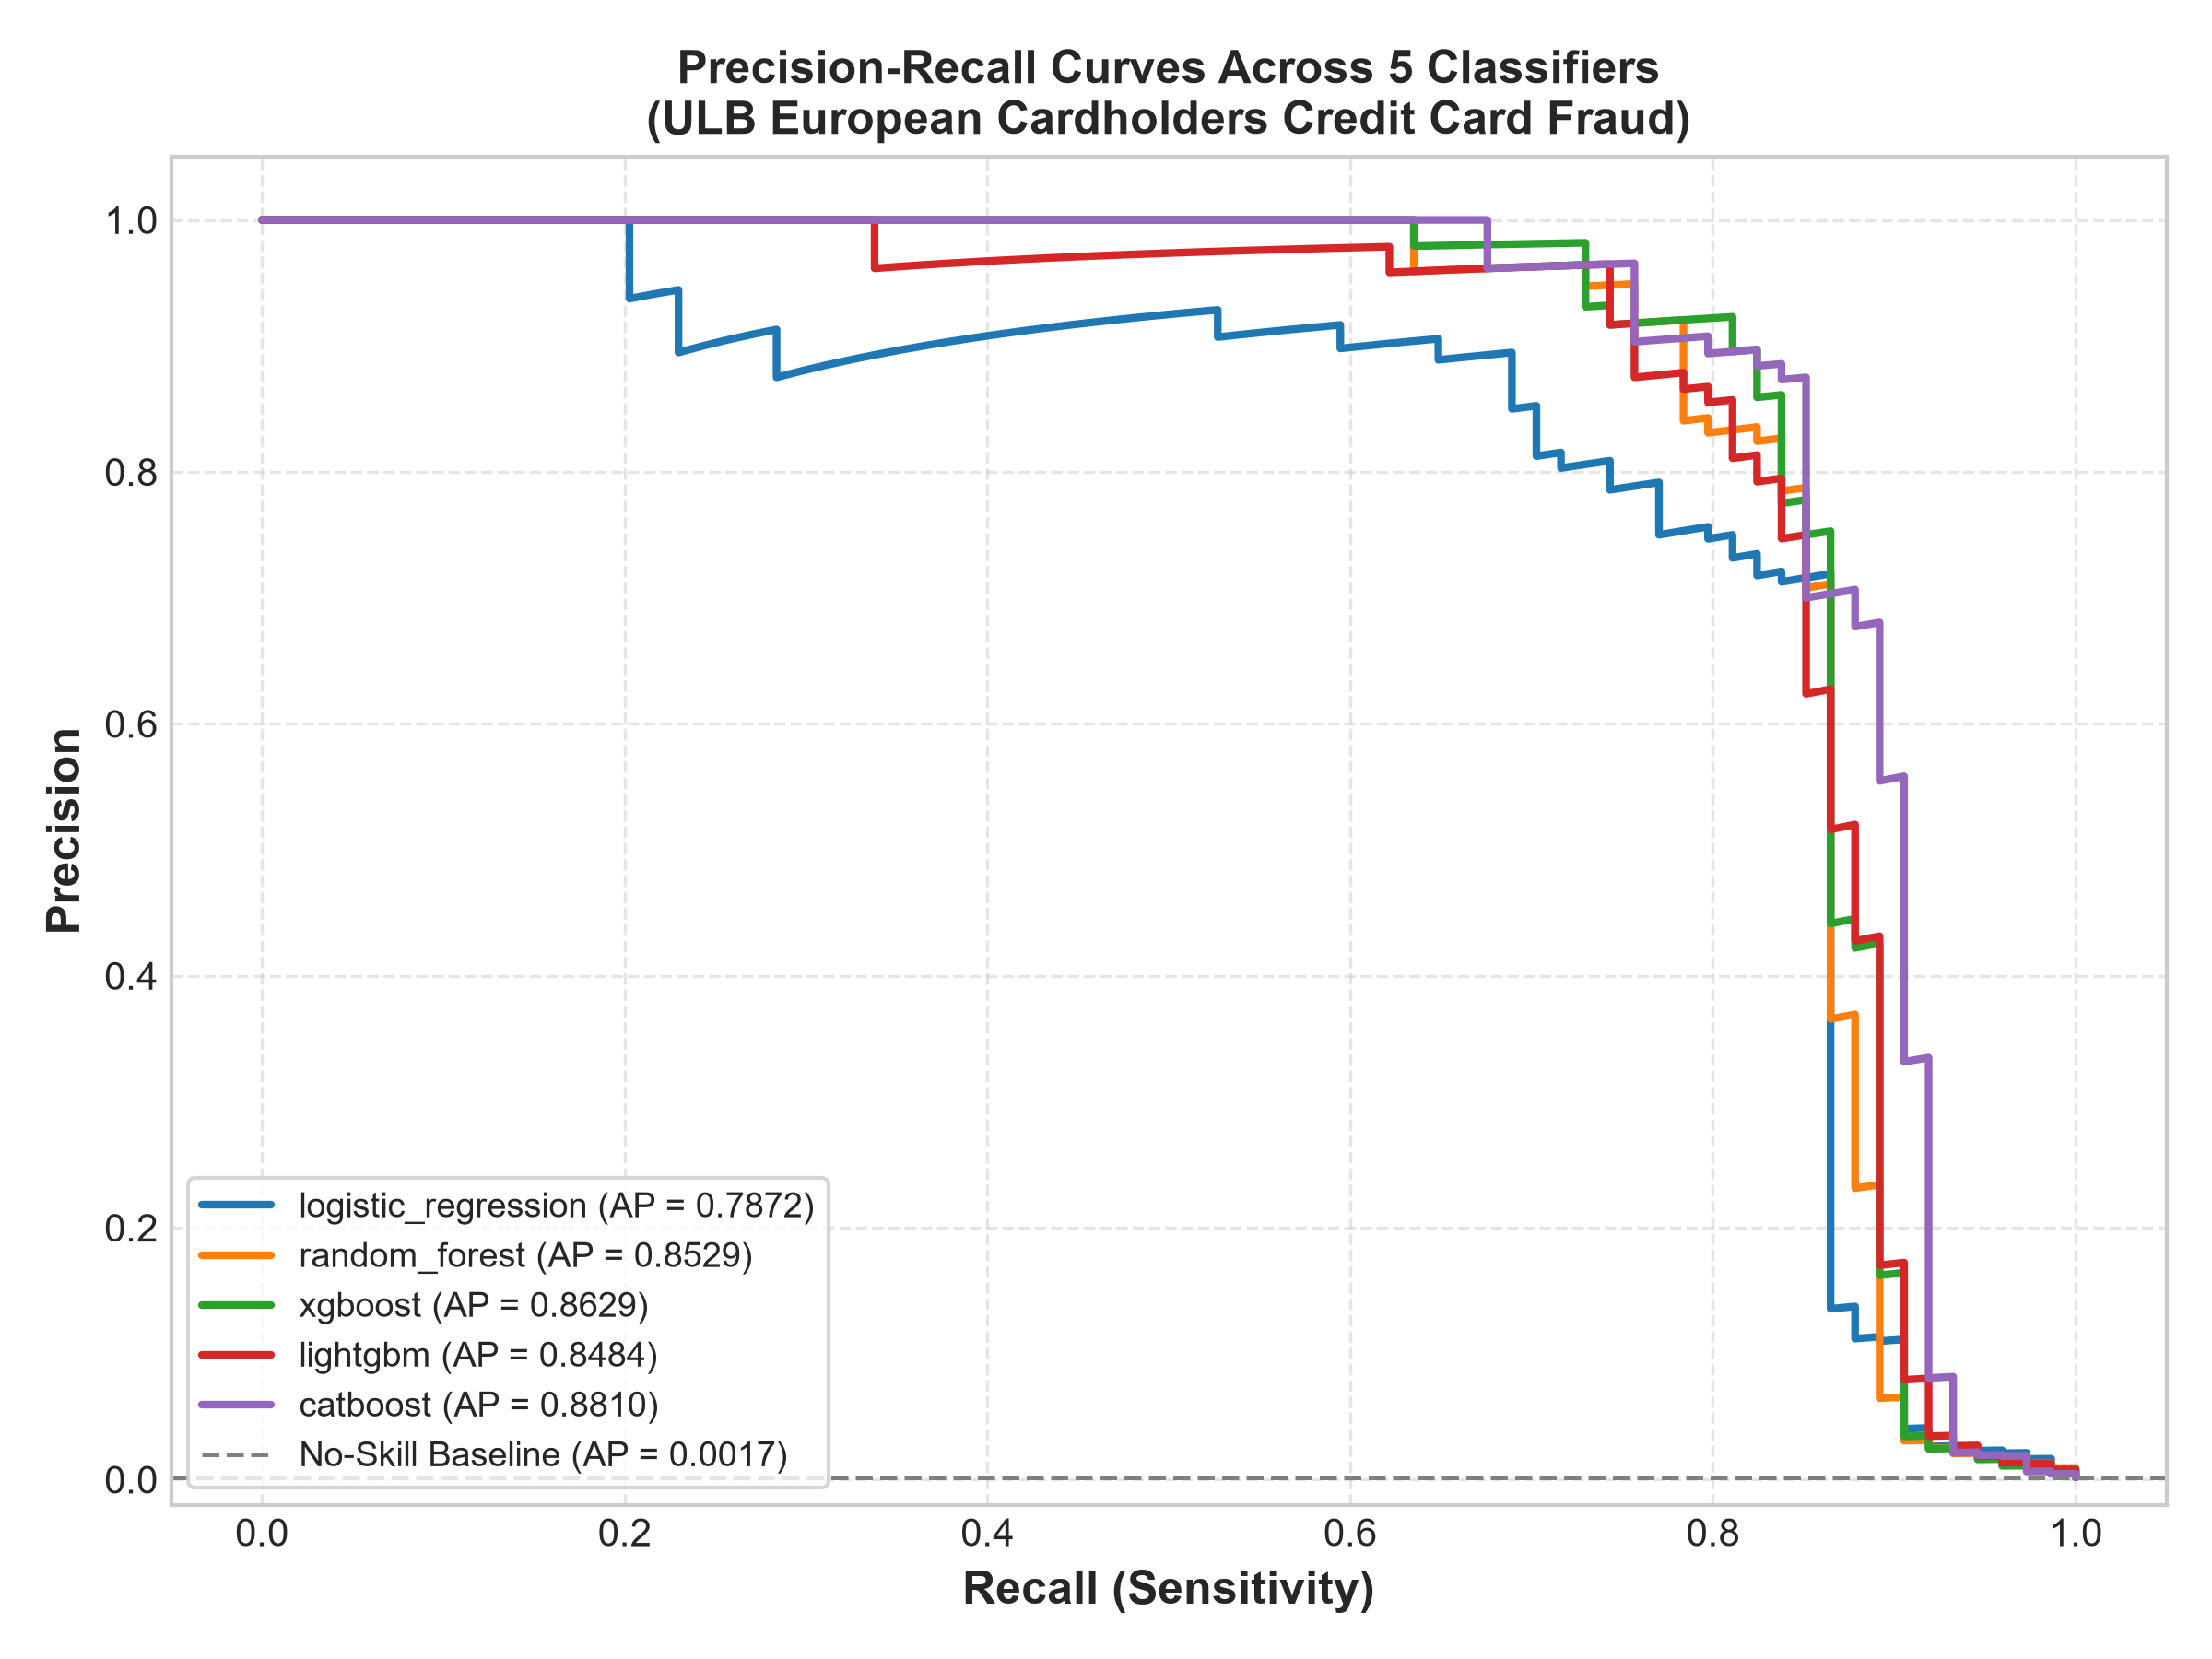

=== confusion_matrices_grid.png ===


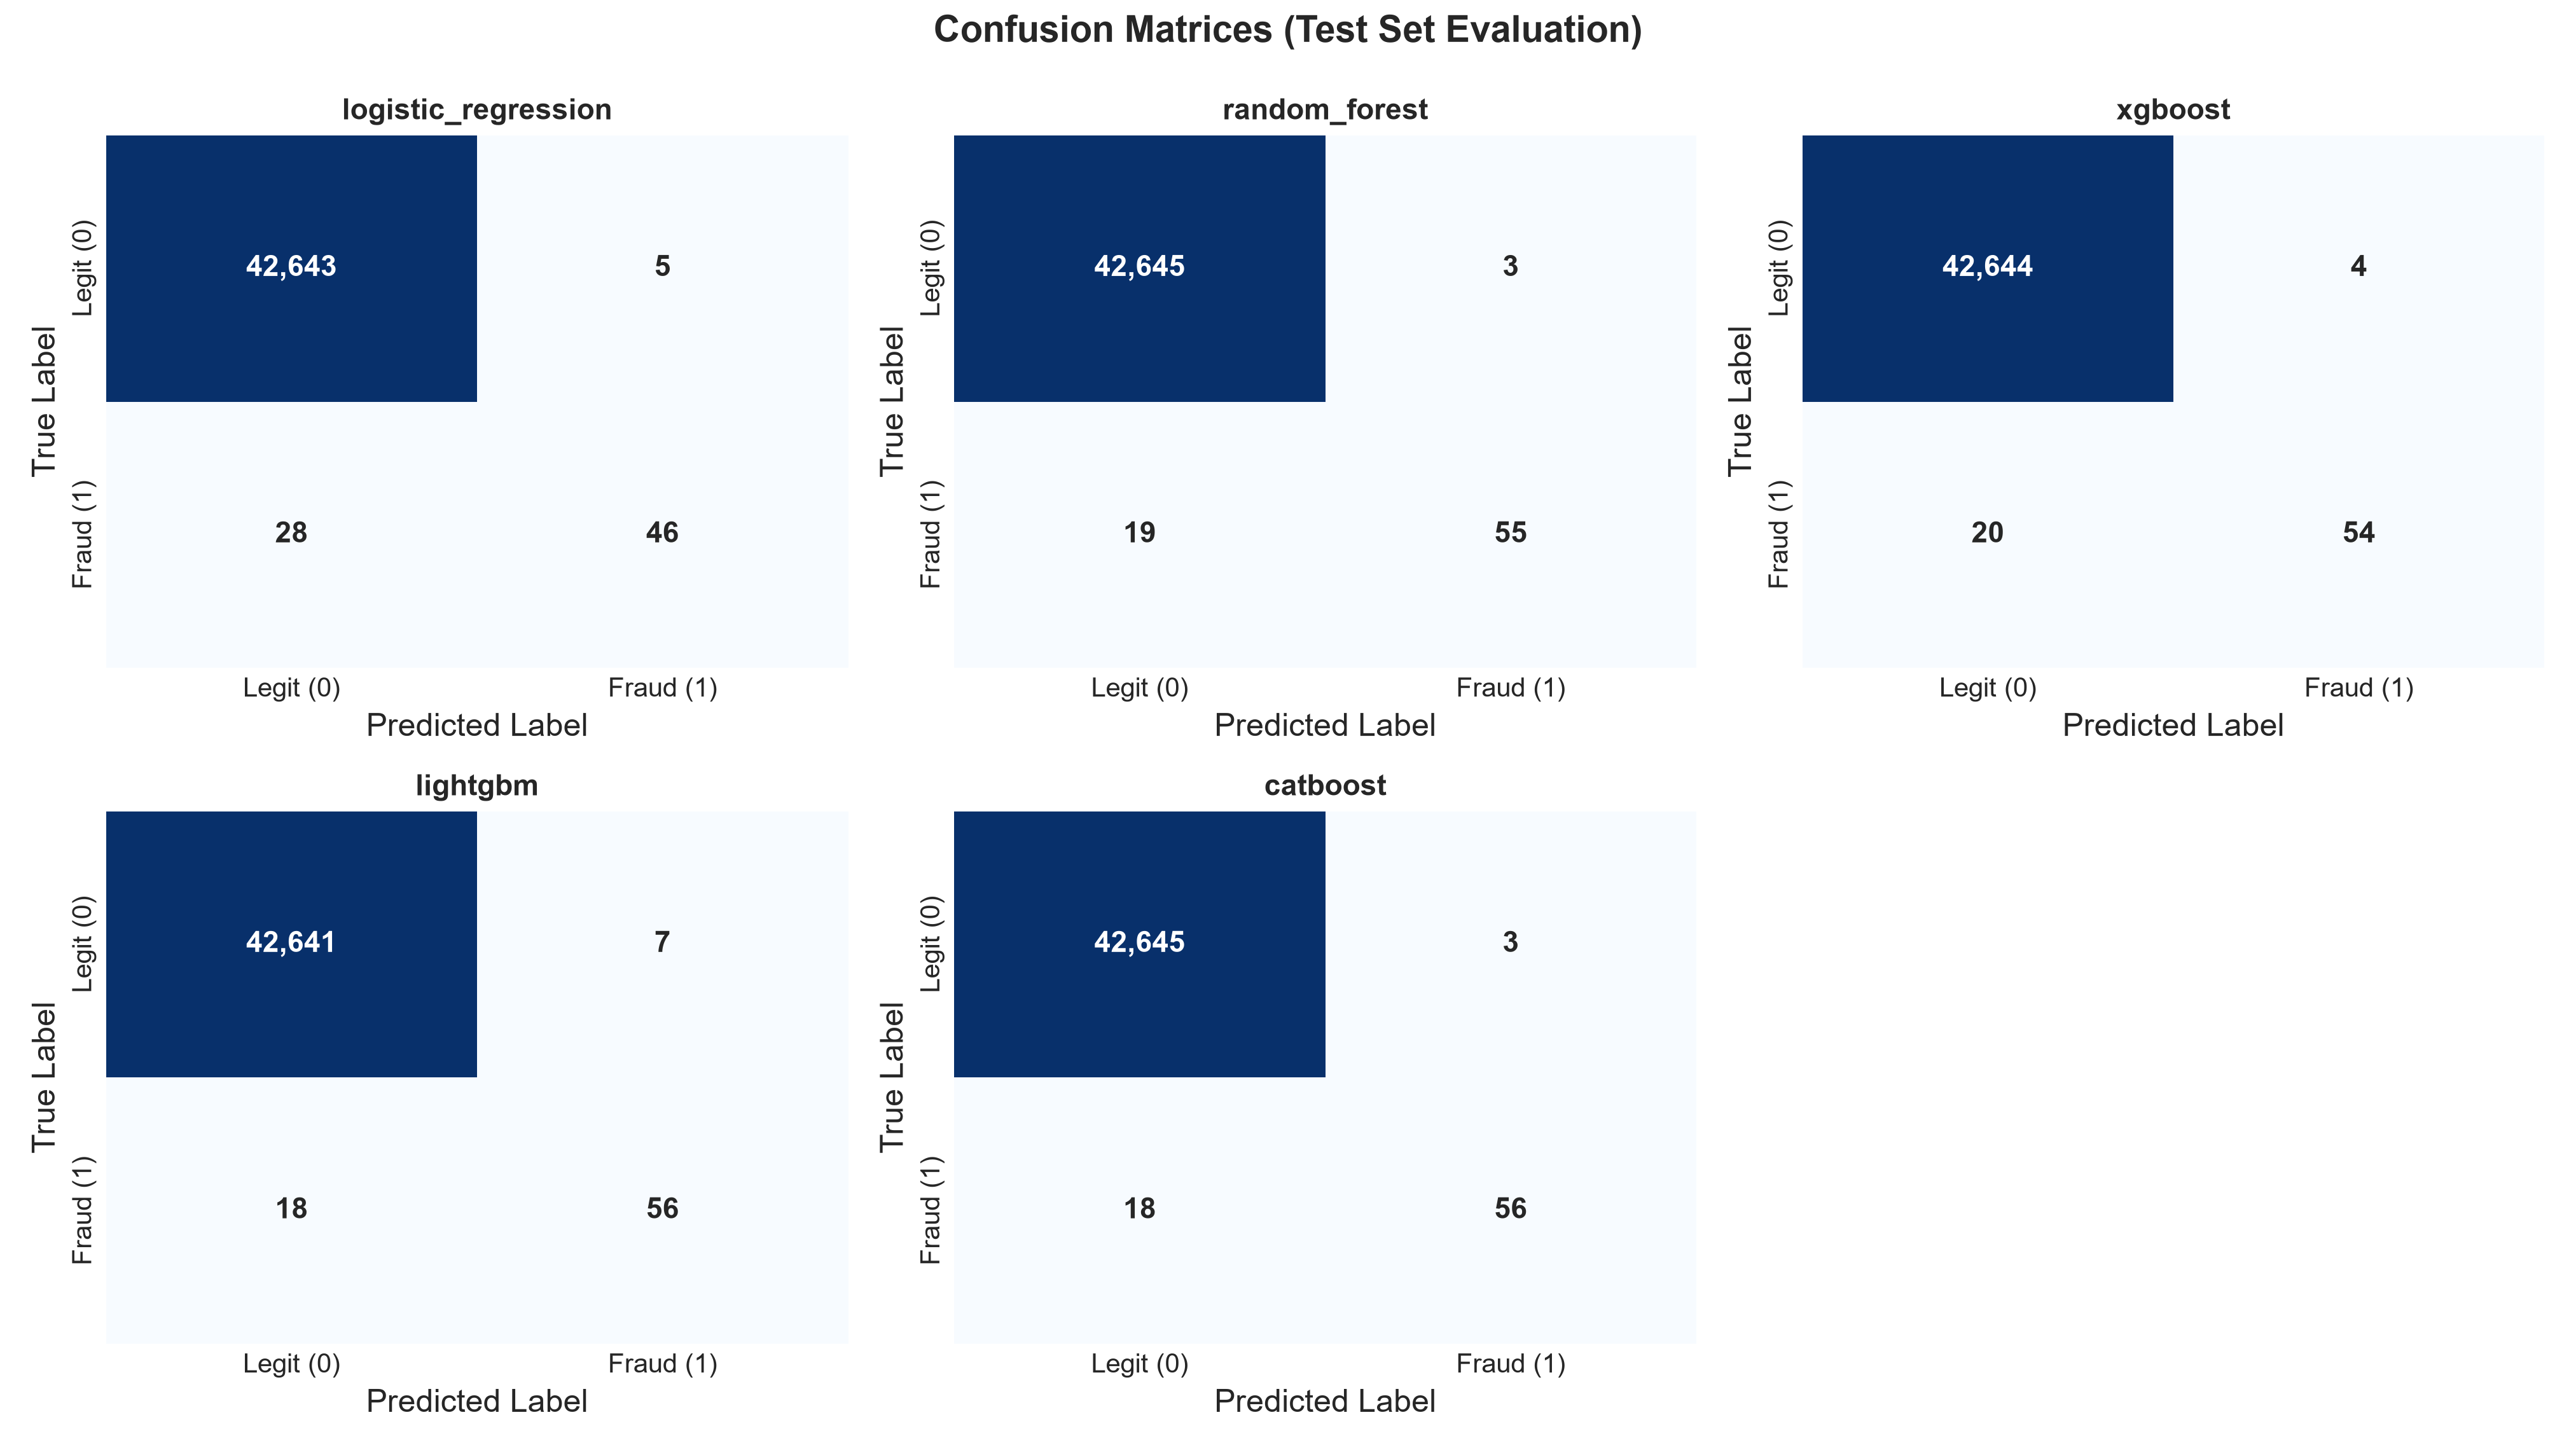

=== threshold_tradeoffs.png ===


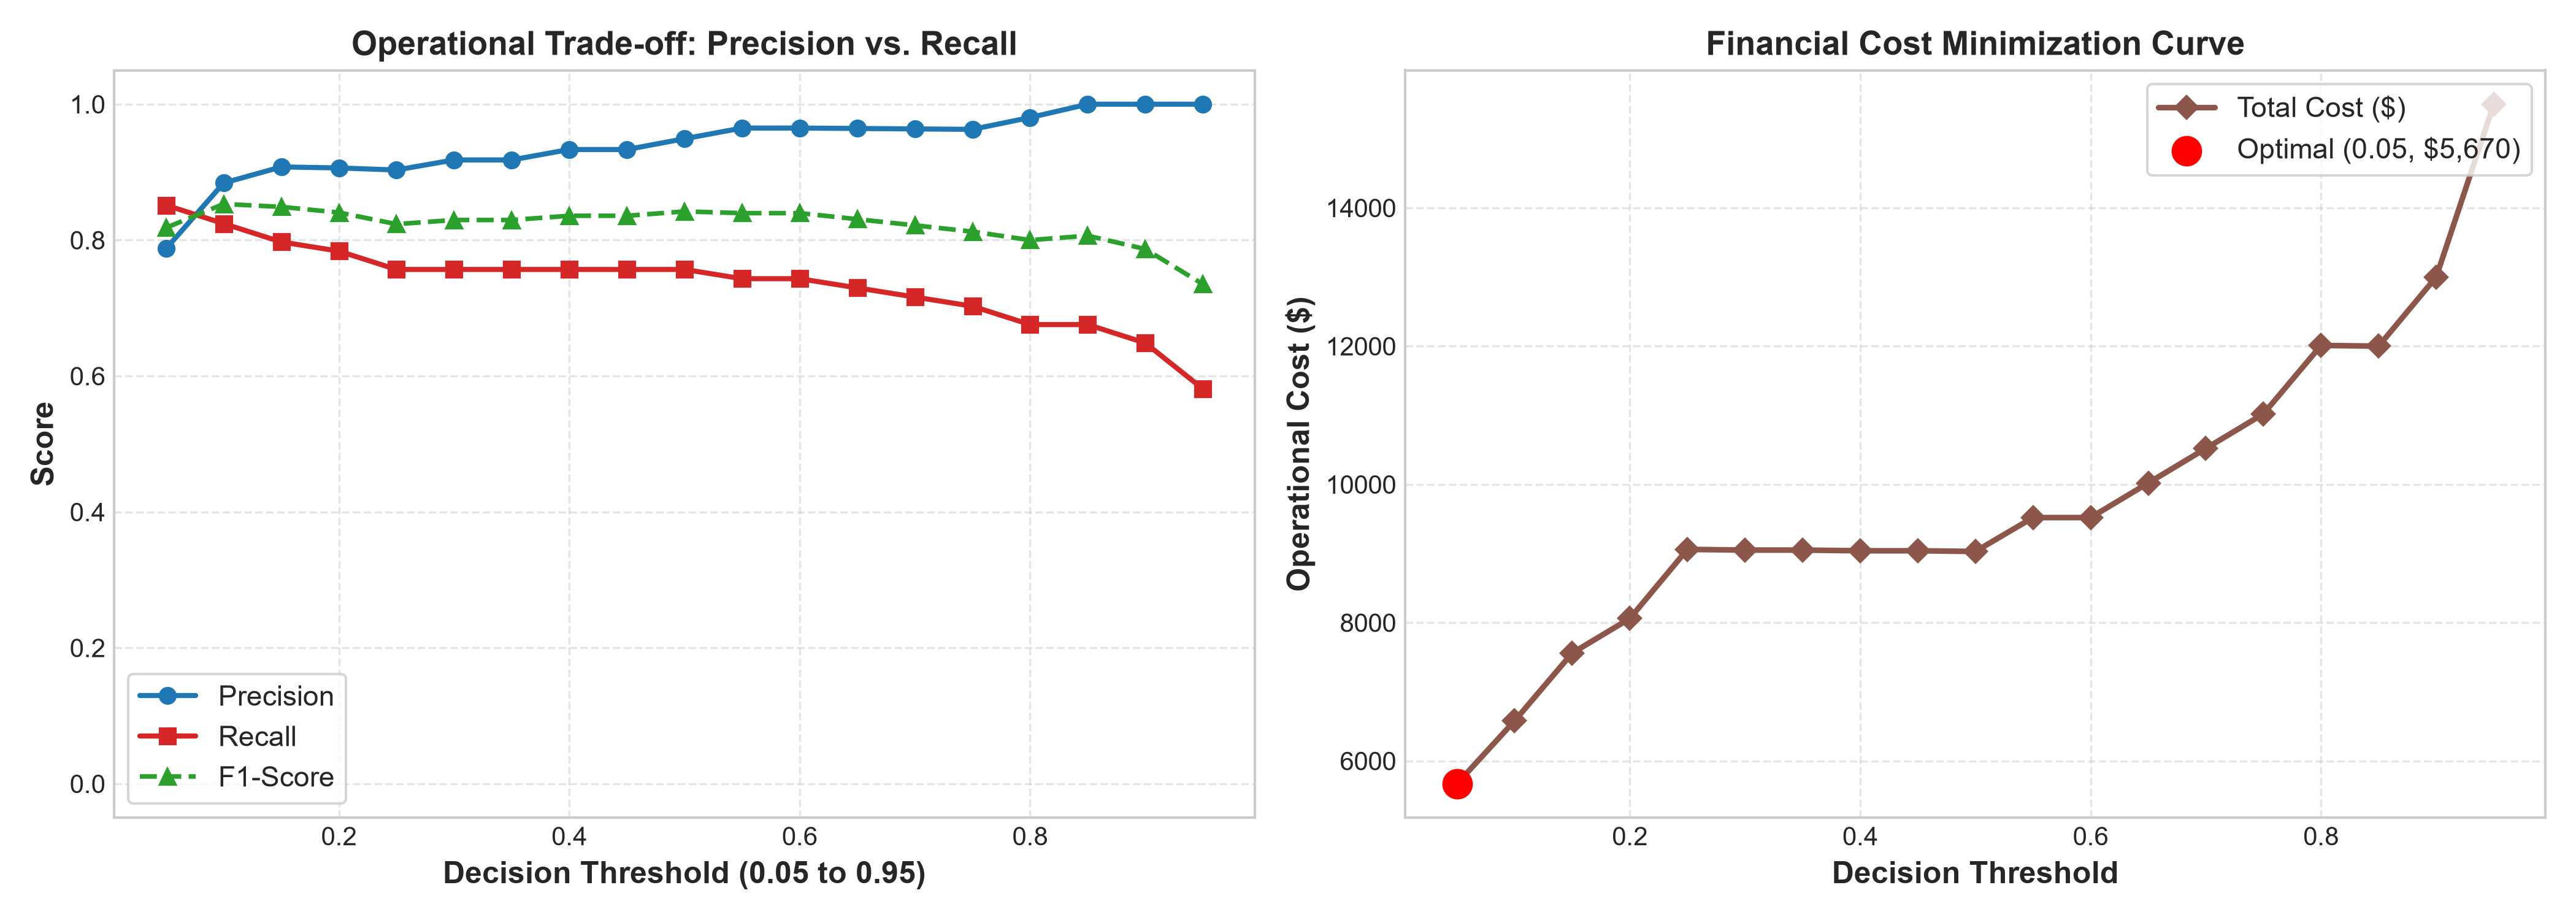

In [4]:
# Display Generated Figures for Dataset B
fig_dir = project_root / "outputs" / "figures" / "dataset_b"
for fname in [
    "eda_overview.png",
    "model_comparison_bar_chart.png",
    "roc_curves.png",
    "pr_curves.png",
    "confusion_matrices_grid.png",
    "threshold_tradeoffs.png",
]:
    fp = fig_dir / fname
    if fp.exists():
        print(f"=== {fname} ===")
        display(Image(filename=str(fp)))

In [5]:
# Cross-Dataset Synthesis (if Dataset A results are also present)
comp_path = project_root / "outputs" / "metrics" / "model_comparison.csv"
if comp_path.exists():
    all_comp = pd.read_csv(comp_path)
    display(all_comp[["dataset_name", "model_name", "precision", "recall", "f1_score", "roc_auc", "pr_auc", "log_loss"]])

cross_fig = project_root / "outputs" / "figures" / "cross_dataset_comparison.png"
if cross_fig.exists():
    display(Image(filename=str(cross_fig)))

spark.stop()

,dataset_name,model_name,precision,recall,f1_score,roc_auc,pr_auc,log_loss
0,ULB European Cardholders Credit Card Fraud,logistic_regression,0.9020,0.6216,0.7360,0.9896,0.7560,0.00386
1,ULB European Cardholders Credit Card Fraud,random_forest,0.9483,0.7432,0.8333,0.9900,0.8537,0.00274
2,ULB European Cardholders Credit Card Fraud,xgboost,0.9310,0.7297,0.8181,0.9887,0.8420,0.00251
3,ULB European Cardholders Credit Card Fraud,lightgbm,0.8889,0.7568,0.8175,0.9904,0.8203,0.00270
4,ULB European Cardholders Credit Card Fraud,catboost,0.9492,0.7568,0.8422,0.9876,0.8592,0.00237
